In [1]:
import polars as pl

# 1. Carregando a base de Desligamentos em modo Lazy
inicial = pl.scan_parquet("C:\\Users\\MICRO\\OneDrive\\Documentos\\UC2\\desligamento_funcionarios.parquet")

# 2. Exibindo o plano de execução/estrutura do arquivo
display(inicial)


In [2]:
import polars as pl

# 1. Carregar a base de desligamentos (Modo Lazy)
inicial = pl.scan_parquet("C:\\Users\\MICRO\\OneDrive\\Documentos\\UC2\\desligamento_funcionarios.parquet")

# 2. Pipeline de métricas adaptado para a coluna 'Salario' e corrigindo o texto para número
metricas1 = inicial.with_columns(
    # Garante que o salário seja numérico (caso ainda não tenha sido tratado)
    pl.col("Salario").cast(pl.String).str.replace(",", ".").cast(pl.Float64)
).select([
    pl.col("Salario").mean().alias("Média"),
    pl.col("Salario").median().alias("Mediana"),
    pl.col("Salario").mode().first().alias("Moda"),
    pl.col("Salario").var().alias("Variância"),
    pl.col("Salario").std().alias("Desvio_Padrão"),
    (pl.col("Salario").max() - pl.col("Salario").min()).alias("Amplitude_Total")
]).collect()

# 3. Exibindo os resultados do Painel de Desligamentos
print("\n--- Estatísticas Descritivas (Salários de Desligamento) ---")
display(metricas1)



--- Estatísticas Descritivas (Salários de Desligamento) ---


Média,Mediana,Moda,Variância,Desvio_Padrão,Amplitude_Total
f64,f64,f64,f64,f64,f64
3699.996228,3575.84,5426.74,1.5487e6,1244.471779,4755.91


In [2]:
import polars as pl

# 1. Carregar a base de desligamentos (Modo Lazy)
inicial = pl.scan_parquet("C:\\Users\\MICRO\\OneDrive\\Documentos\\UC2\\desligamento_funcionarios.parquet")

# 2. Pipeline de Quartis e Forma da Distribuição adaptado para 'Salario'
metricas2 = inicial.with_columns(
    # Tratamento preventivo para garantir que a coluna seja decimal (Float64)
    pl.col("Salario").cast(pl.String).str.replace(",", ".").cast(pl.Float64)
).select([
    pl.col("Salario").quantile(0.25).alias("Q1"),
    pl.col("Salario").quantile(0.50).alias("Q2"),
    pl.col("Salario").quantile(0.75).alias("Q3"),
    pl.col("Salario").skew().alias("Assimetria"),
    pl.col("Salario").kurtosis().alias("Curtose")
]).collect()

print("\n--- Quartis e Forma da Distribuição (Salários de Desligamento) ---")
display(metricas2)

# 3. Análise e Interpretação Estratégica da Assimetria para o RH
assimetria = metricas2["Assimetria"][0]
print(f"\nInterpretação da Assimetria ({assimetria:.2f}):")

if -0.5 <= assimetria <= 0.5:
    print("-> Distribuição Simétrica (Os salários dos funcionários desligados são bem distribuídos)")
elif assimetria > 0.5:
    print("-> Assimétrica Positiva (Existem alguns salários de desligamento muito altos puxando a média para cima)")
else:
    print("-> Assimétrica Negativa (A maior parte das rescisões financeiras está concentrada em salários mais altos)")



--- Quartis e Forma da Distribuição (Salários de Desligamento) ---


Q1,Q2,Q3,Assimetria,Curtose
f64,f64,f64,f64,f64
2607.2,3575.84,4701.68,0.28315,-1.039556



Interpretação da Assimetria (0.28):
-> Distribuição Simétrica (Os salários dos funcionários desligados são bem distribuídos)


In [3]:
import polars as pl

# 1. Carrega os dados da sua tabela de Desligamentos de forma direta (Eager mode)
df_desligamento = pl.read_parquet("C:\\Users\\MICRO\\OneDrive\\Documentos\\UC2\\desligamento_funcionarios.parquet")

# Padroniza os nomes das colunas para letras maiúsculas (Mapeado com base no seu arquivo)
df_desligamento = df_desligamento.rename({
    'Data_Desligamento': 'DATA_DESLIGAMENTO',
    'Genero': 'GENERO',
    'Funcao': 'FUNCAO',
    'Motivo_Desligamento': 'MOTIVO_DESLIGAMENTO',
    'Salario': 'SALARIO'
})

# Trata a string de salários (substitui vírgula por ponto) e garante o tipo numérico Float64
df_desligamento = df_desligamento.with_columns(
    pl.col("SALARIO").cast(pl.String).str.replace(",", ".").cast(pl.Float64)
)

# 2. Calcula matematicamente os Quartis e os Limites usando a coluna "SALARIO"
q1 = df_desligamento["SALARIO"].quantile(0.25)
q3 = df_desligamento["SALARIO"].quantile(0.75)
iqr = q3 - q1

limite_inferior = q1 - (1.5 * iqr)
limite_superior = q3 + (1.5 * iqr)

print(f"--- Diagnóstico Estatístico (Desligamento de Funcionários) ---")
print(f"Limites Teóricos para Outliers: Inferior ({limite_inferior:.2f}) | Superior ({limite_superior:.2f})")

# 3. Filtra os Outliers Reais usando os limites calculados
outliers_reais = df_desligamento.filter(
    (pl.col("SALARIO") < limite_inferior) | (pl.col("SALARIO") > limite_superior)
)

print(f"Quantidade de salários considerados Outliers Matemáticos: {outliers_reais.height}")

# 4. SOLUÇÃO DE NEGÓCIO: Se a matemática der 0 outliers, mostramos o teto e o piso reais da folha de desligados
if outliers_reais.height == 0:
    print("\n💡 Insights de RH: Como não existem outliers no papel, isolamos o Topo e a Base reais dos desligamentos:")
    
    # Pega os maiores salários de desligamento (Top 5)
    topo_folha = df_desligamento.sort("SALARIO", descending=True).head(5)
    print("\n[TOPO] Maiores impactos financeiros em rescisões registrados:")
    display(topo_folha.select(["FUNCAO", "GENERO", "MOTIVO_DESLIGAMENTO", "SALARIO"]))
    
    # Pega os menores salários de desligamento (Piso 5)
    piso_folha = df_desligamento.sort("SALARIO").head(5)
    print("\n[BASE] Menores impactos financeiros em rescisões registrados:")
    display(piso_folha.select(["FUNCAO", "GENERO", "MOTIVO_DESLIGAMENTO", "SALARIO"]))
else:
    print("\nExemplos de valores discrepantes encontrados (Anomalias de Custo Rescisório):")
    display(outliers_reais.select(["FUNCAO", "GENERO", "MOTIVO_DESLIGAMENTO", "SALARIO"]).head())


--- Diagnóstico Estatístico (Desligamento de Funcionários) ---
Limites Teóricos para Outliers: Inferior (-534.52) | Superior (7843.40)
Quantidade de salários considerados Outliers Matemáticos: 0

💡 Insights de RH: Como não existem outliers no papel, isolamos o Topo e a Base reais dos desligamentos:

[TOPO] Maiores impactos financeiros em rescisões registrados:


FUNCAO,GENERO,MOTIVO_DESLIGAMENTO,SALARIO
str,str,str,f64
"""Desenvolvedor Full Stack""","""Masculino""","""Demissão sem Justa Causa""",6458.23
"""Supervisor de Operações""","""Masculino""","""Pedido de Demissão""",6458.12
"""Desenvolvedor Full Stack""","""Masculino""","""Demissão sem Justa Causa""",6457.99
"""Analista de Sistemas""","""Feminino""","""Pedido de Demissão""",6457.86
"""Gerente de Projetos""","""Feminino""","""Pedido de Demissão""",6456.44



[BASE] Menores impactos financeiros em rescisões registrados:


FUNCAO,GENERO,MOTIVO_DESLIGAMENTO,SALARIO
str,str,str,f64
"""Diretor de Operações""","""Feminino""","""Pedido de Demissão""",1702.32
"""Gerente de Projetos""","""Feminino""","""Demissão sem Justa Causa""",1704.51
"""Analista de Recursos Humanos""","""Feminino""","""Demissão sem Justa Causa""",1704.72
"""Analista de Sistemas""","""Não-binário""","""Demissão sem Justa Causa""",1704.74
"""Atendente de Suporte""","""Masculino""","""Demissão sem Justa Causa""",1705.65


c:\Users\MICRO\OneDrive\Documentos\UC2\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 128161 (\N{ELECTRIC LIGHT BULB}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


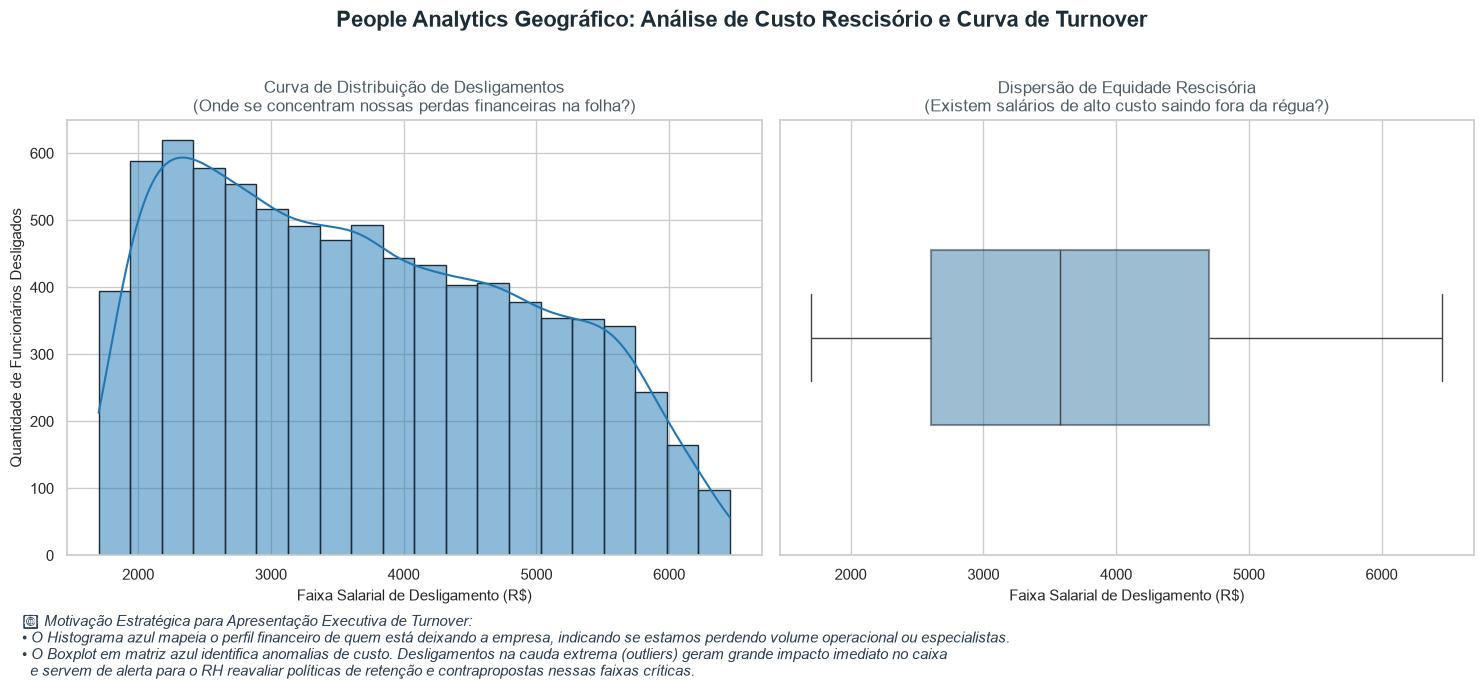

In [4]:
import io
import matplotlib.pyplot as plt
import polars as pl
import seaborn as sns

# ==============================================================================
# 1. TRATAMENTO DOS DADOS (Garantindo tipo numérico no modo Lazy)
# ==============================================================================
# Certifique-se de que a variável 'inicial' do scan_parquet está na memória
visual = (
    inicial.with_columns(
        pl.col("Salario").cast(pl.String).str.replace(",", ".").cast(pl.Float64)
    )
    .select("Salario")
    .collect()
    .to_series()
)

# Definindo um estilo visual mais limpo e profissional
sns.set_theme(style="whitegrid")

# Criando a figura com espaço para um supertítulo e notas de rodapé
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Título Principal focado em Inteligência de Negócio (People Analytics)
plt.suptitle(
    "People Analytics Geográfico: Análise de Custo Rescisório e Curva de Turnover",
    fontsize=16,
    fontweight="bold",
    color="#1c2d37",
    y=1.02,
)

# ==============================================================================
# 2. HISTOGRAMA (Curva de Desligamentos em Azul Corporativo)
# ==============================================================================
sns.histplot(
    visual,
    bins=20,
    kde=True,
    color="#1f77b4",
    ax=axes[0],
    alpha=0.5,
    edgecolor="#1c2d37",
)
axes[0].set_title(
    "Curva de Distribuição de Desligamentos\n(Onde se concentram nossas perdas financeiras na folha?)",
    fontsize=12,
    color="#4f5d65",
)
axes[0].set_xlabel("Faixa Salarial de Desligamento (R$)", fontsize=11)
axes[0].set_ylabel("Quantidade de Funcionários Desligados", fontsize=11)

# ==============================================================================
# 3. BOXPLOT (Dispersão e Equidade Salarial em Variação Azul)
# ==============================================================================
sns.boxplot(
    x=visual,
    color="#2980b9",
    ax=axes[1],
    width=0.4,
    boxprops=dict(alpha=0.5, edgecolor="#1c2d37", linewidth=1.5),
)
axes[1].set_title(
    "Dispersão de Equidade Rescisória\n(Existem salários de alto custo saindo fora da régua?)",
    fontsize=12,
    color="#4f5d65",
)
axes[1].set_xlabel("Faixa Salarial de Desligamento (R$)", fontsize=11)

# ==============================================================================
# 4. NOTA E INSIGHTS DE NEGÓCIO (People Analytics Regional)
# ==============================================================================
motivacao_texto = (
    "💡 Motivação Estratégica para Apresentação Executiva de Turnover:\n"
    "• O Histograma azul mapeia o perfil financeiro de quem está deixando a empresa, indicando se estamos perdendo volume operacional ou especialistas.\n"
    "• O Boxplot em matriz azul identifica anomalias de custo. Desligamentos na cauda extrema (outliers) geram grande impacto imediato no caixa\n"
    "  e servem de alerta para o RH reavaliar políticas de retenção e contrapropostas nessas faixas críticas."
)
plt.figtext(
    0.02,
    -0.09,
    motivacao_texto,
    fontsize=11,
    color="#2c3e50",
    style="italic",
    horizontalalignment="left",
)

plt.tight_layout()
plt.show()


c:\Users\MICRO\OneDrive\Documentos\UC2\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 127919 (\N{DIRECT HIT}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


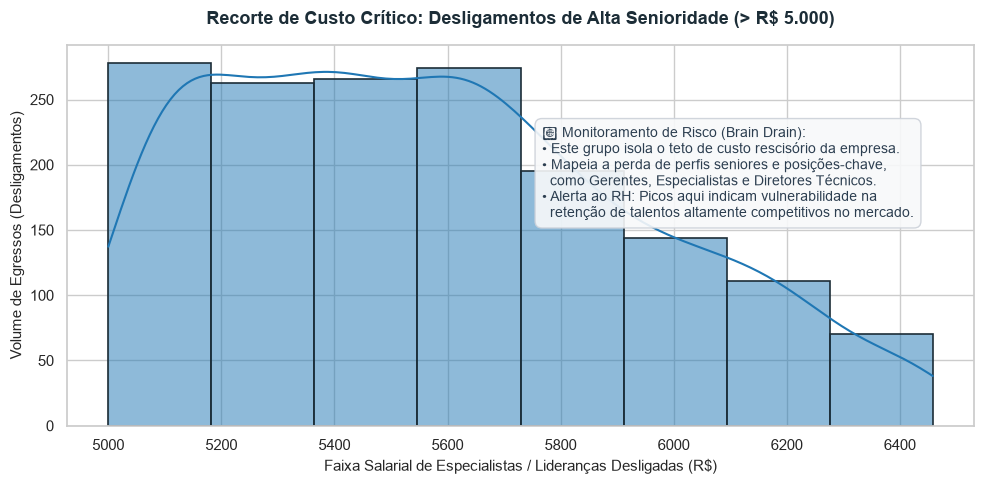

In [ ]:
import io
import matplotlib.pyplot as plt
import polars as pl
import seaborn as sns
# ==============================================================================
# 1. FILTRAGEM E TRATAMENTO DOS DADOS (Modo Lazy)
# ==============================================================================
# Filtramos os salários acima de R$ 5.000 da base de desligados
visual_superiores = (
    inicial.with_columns(
        pl.col("Salario").cast(pl.String).str.replace(",", ".").cast(pl.Float64)
    )
    .filter(pl.col("Salario") > 5000)
    .select("Salario")
    .collect()
    .to_series()
)

# Configurando o tema de fundo do gráfico
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 5))

# ==============================================================================
# 2. GERAR O HISTOGRAMA EM AZUL CORPORATIVO (Mantenha o padrão de matriz)
# ==============================================================================
# Alterado para o azul (#1f77b4) com alpha=0.5 para combinar com seus gráficos anteriores
sns.histplot(
    visual_superiores,
    kde=True,
    color="#1f77b4",
    bins=8,
    alpha=0.5,
    edgecolor="#1c2d37",
    linewidth=1.2,
)

# Títulos e legendas motivacionais focadas em Retenção e Custo de Saída
plt.title(
    "Recorte de Custo Crítico: Desligamentos de Alta Senioridade (> R$ 5.000)",
    fontsize=13,
    fontweight="bold",
    color="#1c2d37",
    pad=15,
)
plt.xlabel(
    "Faixa Salarial de Especialistas / Lideranças Desligadas (R$)", fontsize=11
)
plt.ylabel("Volume de Egressos (Desligamentos)", fontsize=11)

# ==============================================================================
# 3. CAIXA DE TEXTO EXPLICATIVA (Mapeamento de Riscos de People Analytics)
# ==============================================================================
texto_insights = (
    "🎯 Monitoramento de Risco (Brain Drain):\n"
    "• Este grupo isola o teto de custo rescisório da empresa.\n"
    "• Mapeia a perda de perfis seniores e posições-chave,\n"
    "  como Gerentes, Especialistas e Diretores Técnicos.\n"
    "• Alerta ao RH: Picos aqui indicam vulnerabilidade na\n"
    "  retenção de talentos altamente competitivos no mercado."
)
plt.figtext(
    0.55,
    0.55,
    texto_insights,
    fontsize=10,
    color="#2c3e50",
    bbox=dict(
        facecolor="#f8f9fa",
        alpha=0.9,
        edgecolor="#ccd1d9",
        boxstyle="round,pad=0.5",
    ),
)

plt.tight_layout()
plt.show()


In [7]:
import polars as pl

# Certifique-se de que a variável 'inicial' está carregada na memória com a base de desligados

# 1. Transformar em LAZY e Criar o DataFrame Agregado por Função (Adaptado para Desligamentos)
df_funcoes = inicial.lazy().group_by("Funcao").agg([
    pl.len().alias("Qtd_Desligamentos"),  # Volume de demissões na função (Variável X)
    # Tratamento da vírgula para ponto e conversão para número real
    pl.col("Salario").cast(pl.String).str.replace(",", ".").cast(pl.Float64).mean().alias("Salario_Medio") # Salário médio (Variável Y)
])

# 2. Calcular a Correlação de Pearson entre Volume de Demissões e Salário Médio
correlacao = df_funcoes.select(
    pl.corr("Qtd_Desligamentos", "Salario_Medio", method="pearson").alias("r")
).collect()

r = correlacao["r"][0]
r2 = r**2

print(f"--- Análise de Correlação Estratégica (Turnover / Desligamentos) ---")
print(f"Coeficiente de Pearson (r): {r:.4f}")
print(f"Coeficiente de Determinação (r²): {r2:.4f}\n")

# 3. Interpretação e Motivação de People Analytics para o RH (Foco em Retenção)
if abs(r) < 0.3:
    print("Conclusão: Correlação FRACA.")
    print("-> Motivação de RH: O volume de demissões é independente do salário. O turnover está acontecendo de forma dispersa em todas as faixas salariais, indicando que a insatisfação ou a perda de talentos não está atrelada estritamente ao fator remuneração da tabela.")
elif r < -0.3:
    print("Conclusão: Correlação NEGATIVA.")
    print("-> Motivação de RH: Estrutura piramidal saudável mantida na saída. As funções com maior volume de desligamentos possuem os menores salários médios (ex: perfis operacionais). Isso protege o fluxo de caixa, pois as rescisões individuais têm menor impacto financeiro.")
else:
    print("Conclusão: Correlação POSITIVA.")
    print("-> Motivação de RH: Alerta Crítico de Custo e Fuga de Cérebros (Brain Drain). As funções com maior número de demissões são justamente aquelas com os salários mais altos. A empresa está perdendo posições estratégicas e caras, o que inflaciona o custo de rescisão e exige revisão urgente dos planos de retenção.")


--- Análise de Correlação Estratégica (Turnover / Desligamentos) ---
Coeficiente de Pearson (r): -0.3388
Coeficiente de Determinação (r²): 0.1148

Conclusão: Correlação NEGATIVA.
-> Motivação de RH: Estrutura piramidal saudável mantida na saída. As funções com maior volume de desligamentos possuem os menores salários médios (ex: perfis operacionais). Isso protege o fluxo de caixa, pois as rescisões individuais têm menor impacto financeiro.


c:\Users\MICRO\OneDrive\Documentos\UC2\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 128161 (\N{ELECTRIC LIGHT BULB}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


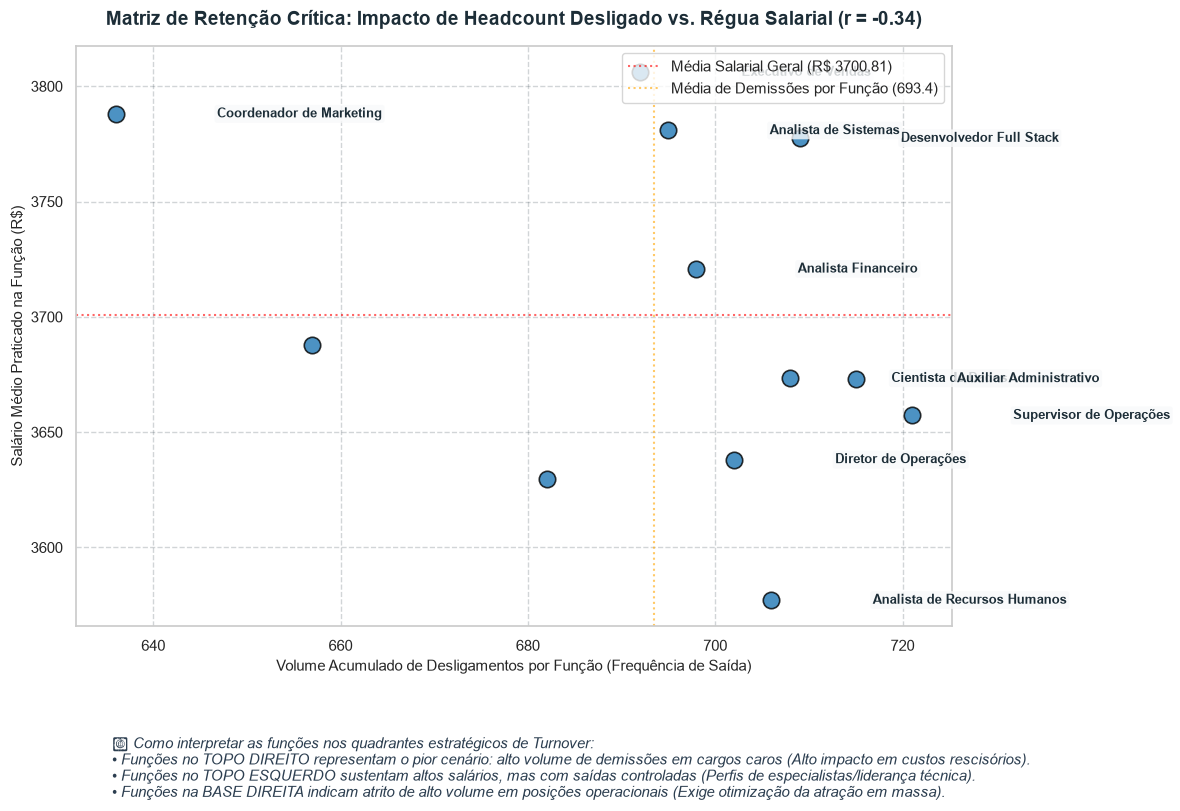

In [11]:
import matplotlib.pyplot as plt
import polars as pl
import seaborn as sns

# ==============================================================================
# 1. CARREGAMENTO E AGRUPAMENTO DOS DADOS (MODO LAZY)
# ==============================================================================
# Lendo a base física de desligamentos que salvamos anteriormente
inicial = pl.scan_parquet(
    "C:\\Users\\MICRO\\OneDrive\\Documentos\\UC2\\desligamento_funcionarios.parquet"
)

# Agrupando por Função e tratando o salário de texto para número real
df_funcoes = inicial.group_by("Funcao").agg(
    [
        pl.len().alias("Qtd_Desligamentos"),
        pl.col("Salario")
        .cast(pl.String)
        .str.replace(",", ".")
        .cast(pl.Float64)
        .mean()
        .alias("Salario_Medio"),
    ]
)

# Calcular a Correlação de Pearson entre o Volume e o Salário Médio
correlacao = df_funcoes.select(
    pl.corr("Qtd_Desligamentos", "Salario_Medio", method="pearson").alias("r")
).collect()

# Extraindo os valores escalares finais para o gráfico
r = correlacao["r"][0]

# Convertendo a base agregada final para Pandas para plotagem no Seaborn
df_pandas = df_funcoes.collect().to_pandas()

# ==============================================================================
# 2. INTERFACE GRÁFICA (MATRIZ DE DISPERSÃO AZUL)
# ==============================================================================
sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 7))

# Criando o gráfico de dispersão com marcadores azuis corporativos
sns.scatterplot(
    data=df_pandas,
    x="Qtd_Desligamentos",
    y="Salario_Medio",
    s=140,
    color="#1f77b4",  # Azul clássico das bolhas anteriores
    alpha=0.8,
    edgecolor="black",
    linewidth=1.2,
)

# 3. DESTACANDO AS FUNÇÕES CRÍTICAS (Anotações automáticas seguras)
max_x = df_pandas["Qtd_Desligamentos"].max()

for i in range(len(df_pandas)):
    funcao = df_pandas.iloc[i]["Funcao"]
    x = df_pandas.iloc[i]["Qtd_Desligamentos"]
    y = df_pandas.iloc[i]["Salario_Medio"]

    # Condição para destacar: Se a função estiver acima da média de demissões ou salário
    if (
        x > df_pandas["Qtd_Desligamentos"].mean() * 1.0
        or y > df_pandas["Salario_Medio"].mean() * 1.0
    ):
        plt.text(
            x + (max_x * 0.015),
            y,
            s=funcao,
            fontsize=9,
            fontweight="bold",
            color="#1c2d37",
            va="center",
            bbox=dict(
                facecolor="#f8f9fa",
                alpha=0.8,
                edgecolor="none",
                boxstyle="round,pad=0.2",
            ),
        )

# Títulos e Legendas focados em Retenção e Inteligência de Custo Rescisório
plt.title(
    f"Matriz de Retenção Crítica: Impacto de Headcount Desligado vs. Régua Salarial (r = {r:.2f})",
    fontsize=14,
    fontweight="bold",
    color="#1c2d37",
    pad=15,
)
plt.xlabel(
    "Volume Acumulado de Desligamentos por Função (Frequência de Saída)",
    fontsize=11,
)
plt.ylabel("Salário Médio Praticado na Função (R$)", fontsize=11)
plt.grid(True, alpha=0.2, linestyle="--", color="#1c2d37")

# Adicionando linhas de referência (médias gerais) para criar os quadrantes estratégicos
media_salarial = df_pandas["Salario_Medio"].mean()
media_desligamentos = df_pandas["Qtd_Desligamentos"].mean()

plt.axhline(
    media_salarial,
    color="red",
    linestyle=":",
    alpha=0.6,
    label=f"Média Salarial Geral (R$ {media_salarial:.2f})",
)
plt.axvline(
    media_desligamentos,
    color="orange",
    linestyle=":",
    alpha=0.6,
    label=f"Média de Demissões por Função ({media_desligamentos:.1f})",
)
plt.legend(loc="upper right")

# Texto motivacional de rodapé estendido para a tomada de decisão do RH
texto_motivacao = (
    "💡 Como interpretar as funções nos quadrantes estratégicos de Turnover:\n"
    "• Funções no TOPO DIREITO representam o pior cenário: alto volume de demissões em cargos caros (Alto impacto em custos rescisórios).\n"
    "• Funções no TOPO ESQUERDO sustentam altos salários, mas com saídas controladas (Perfis de especialistas/liderança técnica).\n"
    "• Funções na BASE DIREITA indicam atrito de alto volume em posições operacionais (Exige otimização da atração em massa)."
)
plt.figtext(
    0.10,
    -0.15,
    s=texto_motivacao,
    fontsize=10.5,
    color="#2c3e50",
    style="italic",
    horizontalalignment="left",
)

plt.tight_layout()
plt.show()


In [29]:
import polars as pl


# ============================================================
# 1. CAMINHO DO ARQUIVO CSV
# ============================================================

arquivo_csv = (
    r"C:\Users\MICRO\OneDrive\Documentos\UC2"
    r"\Desligamento_funcionarios.csv"
)

# ============================================================
# 2. LEITURA DO CSV
# ============================================================

df_desligamentos = pl.read_csv(
    arquivo_csv,
    separator=";",
    encoding="windows-1252",
    infer_schema_length=10000
)

# ============================================================
# 3. TRATAMENTO DOS SALÁRIOS
# ============================================================

df_desligamentos = df_desligamentos.with_columns(
    pl.col("Salario")
    .cast(pl.String)
    .str.replace(",", ".")
    .cast(pl.Float64)
    .alias("Salario")
)

# ============================================================
# 4. AGRUPAMENTO POR FUNÇÃO
#    QUANTIDADE DE DESLIGAMENTOS E SALÁRIO MÉDIO
# ============================================================

df_cargos = (
    df_desligamentos
    .group_by("Funcao")
    .agg([
        pl.len().alias("Qtd_Desligamento"),
        pl.col("Salario").mean().alias("Salario_Medio")
    ])
    .sort("Funcao")
    .lazy()
)

# ============================================================
# 5. CÁLCULO DAS CORRELAÇÕES DE PEARSON E SPEARMAN
# ============================================================

analise_correlacao = df_cargos.select([
    pl.corr(
        "Qtd_Desligamento",
        "Salario_Medio",
        method="pearson"
    ).alias("Pearson"),

    pl.corr(
        "Qtd_Desligamento",
        "Salario_Medio",
        method="spearman"
    ).alias("Spearman")
]).collect()

# ============================================================
# 6. EXIBIÇÃO DOS RESULTADOS
# ============================================================

print(
    "\n--- Coeficientes de Correlação "
    "(Desligamento de Funcionários) ---"
)

print(analise_correlacao)

# ============================================================
# 7. EXTRAÇÃO DOS COEFICIENTES
# ============================================================

r_pearson = analise_correlacao["Pearson"][0]
r_spearman = analise_correlacao["Spearman"][0]

# ============================================================
# 8. INTERPRETAÇÃO PARA PEOPLE ANALYTICS
# ============================================================

print("\nMotivação de People Analytics para o RH:")

print(
    f"• Pearson ({r_pearson:.4f}): "
    "Avalia a relação linear entre a quantidade de "
    "desligamentos por função e o salário médio dessas funções."
)

print(
    f"• Spearman ({r_spearman:.4f}): "
    "Avalia a relação entre os rankings da quantidade de "
    "desligamentos e dos salários médios por função."
)

# ============================================================
# 9. EXIBIÇÃO DA TABELA AGREGADA
# ============================================================

print("\n--- Dados Agregados por Função ---")

print(df_cargos.collect())



--- Coeficientes de Correlação (Desligamento de Funcionários) ---
shape: (1, 2)
┌───────────┬───────────┐
│ Pearson   ┆ Spearman  │
│ ---       ┆ ---       │
│ f64       ┆ f64       │
╞═══════════╪═══════════╡
│ -0.338795 ┆ -0.377622 │
└───────────┴───────────┘

Motivação de People Analytics para o RH:
• Pearson (-0.3388): Avalia a relação linear entre a quantidade de desligamentos por função e o salário médio dessas funções.
• Spearman (-0.3776): Avalia a relação entre os rankings da quantidade de desligamentos e dos salários médios por função.

--- Dados Agregados por Função ---
shape: (12, 3)
┌──────────────────────────────┬──────────────────┬───────────────┐
│ Funcao                       ┆ Qtd_Desligamento ┆ Salario_Medio │
│ ---                          ┆ ---              ┆ ---           │
│ str                          ┆ u32              ┆ f64           │
╞══════════════════════════════╪══════════════════╪═══════════════╡
│ Analista Financeiro          ┆ 698              ┆ 3720

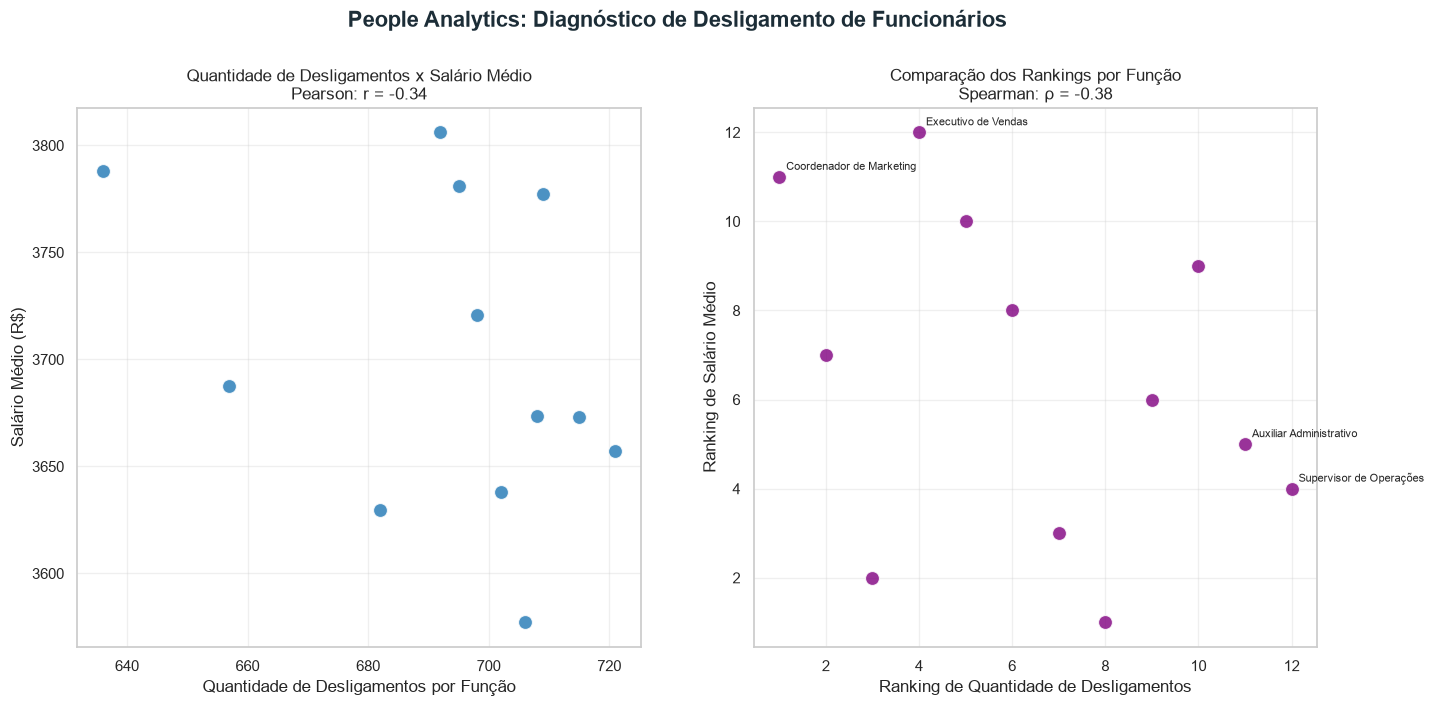

In [31]:

import matplotlib.pyplot as plt
import seaborn as sns
import polars as pl

# ============================================================
# 1. PREPARAR OS DADOS DE DESLIGAMENTO DE FUNCIONÁRIOS
#    COM OS RANKINGS DE SPEARMAN
# ============================================================

df_spearman = df_cargos.with_columns([
    pl.col("Qtd_Desligamento").rank().alias("Rank_Qtd"),
    pl.col("Salario_Medio").rank().alias("Rank_Salario")
]).collect()

# Converter os dados para Pandas para criar os gráficos
df_pandas = df_spearman.to_pandas()

# ============================================================
# 2. CALCULAR AS CORRELAÇÕES
# ============================================================

r_pearson = df_pandas[
    ["Qtd_Desligamento", "Salario_Medio"]
].corr(method="pearson").iloc[0, 1]

r_spearman = df_pandas[
    ["Qtd_Desligamento", "Salario_Medio"]
].corr(method="spearman").iloc[0, 1]

# ============================================================
# 3. CONFIGURAÇÃO VISUAL
# ============================================================

sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

fig.suptitle(
    "People Analytics: Diagnóstico de Desligamento de Funcionários",
    fontsize=16,
    fontweight="bold",
    color="#1c2d37",
    y=1.02
)

# ============================================================
# 4. GRÁFICO 1: DADOS BRUTOS — VISÃO DE PEARSON
# ============================================================

sns.scatterplot(
    data=df_pandas,
    x="Qtd_Desligamento",
    y="Salario_Medio",
    ax=axes[0],
    s=100,
    color="#1f77b4",
    alpha=0.8
)

axes[0].set_title(
    f"Quantidade de Desligamentos x Salário Médio\n"
    f"Pearson: r = {r_pearson:.2f}",
    fontsize=12
)

axes[0].set_xlabel("Quantidade de Desligamentos por Função")
axes[0].set_ylabel("Salário Médio (R$)")
axes[0].grid(True, alpha=0.3)

# Identificar funções com valores elevados
media_salario = df_pandas["Salario_Medio"].mean()
media_desligamentos = df_pandas["Qtd_Desligamento"].mean()

for _, row in df_pandas.iterrows():
    if (
        row["Salario_Medio"] > media_salario * 1.2
        or row["Qtd_Desligamento"] > media_desligamentos * 1.3
    ):
        axes[0].annotate(
            str(row["Funcao"]),
            (
                row["Qtd_Desligamento"],
                row["Salario_Medio"]
            ),
            xytext=(5, 5),
            textcoords="offset points",
            fontsize=8
        )

# ============================================================
# 5. GRÁFICO 2: RANKINGS — VISÃO DE SPEARMAN
# ============================================================

sns.scatterplot(
    data=df_pandas,
    x="Rank_Qtd",
    y="Rank_Salario",
    ax=axes[1],
    s=100,
    color="purple",
    alpha=0.8
)

axes[1].set_title(
    f"Comparação dos Rankings por Função\n"
    f"Spearman: ρ = {r_spearman:.2f}",
    fontsize=12
)

axes[1].set_xlabel(
    "Ranking de Quantidade de Desligamentos"
)

axes[1].set_ylabel(
    "Ranking de Salário Médio"
)

axes[1].grid(True, alpha=0.3)

# Identificar funções nos extremos dos rankings
max_rank_qtd = df_pandas["Rank_Qtd"].max()
max_rank_salario = df_pandas["Rank_Salario"].max()

for _, row in df_pandas.iterrows():
    if (
        row["Rank_Salario"] > max_rank_salario - 2
        or row["Rank_Qtd"] > max_rank_qtd - 2
    ):
        axes[1].annotate(
            str(row["Funcao"]),
            (row["Rank_Qtd"], row["Rank_Salario"]),
            xytext=(5, 5),
            textcoords="offset points",
            fontsize=8
        )

# ============================================================
# ============================================================



In [32]:
import numpy as np
import polars as pl
from datetime import datetime
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression

In [96]:
import polars as pl

# 1. Carregando a base usando 'utf8-lossy' para ignorar caracteres corrompidos
inicial = pl.scan_csv(
    "Desligamento_funcionarios.csv",
    separator=";",
    schema_overrides={"Salario": pl.String},
    encoding="utf8-lossy",  # <-- Alterado para o formato aceito pelo Polars
)

# 2, 3, 4 e 5. Pipeline de transformações e execução
df_final = (
    inicial
    # 2. Padronizando os nomes das colunas
    .rename(
        {
            "Data_Desligamento": "DATA_DESLIGAMENTO",
            "Genero": "GENERO",
            "Funcao": "CARGO",
            "Motivo_Desligamento": "MOTIVO_DESLIGAMENTO",
            "Salario": "SALARIOS",
        }
    )
    # 3. Substituindo vírgula por ponto e convertendo para Float64 com segurança
    .with_columns(
        pl.col("SALARIOS")
        .str.replace(",", ".", literal=True)
        .cast(pl.Float64)
    )
    # 4. Convertendo a data de string para o tipo Date/Datetime real
    .with_columns(
        pl.col("DATA_DESLIGAMENTO")
        .str.to_datetime(format="%d/%m/%Y %H:%M", strict=False)
        .alias("DATA_DESLIGAMENTO_REF")
    )
)

# 5. Executando o pipeline final
display(df_final.collect())


DATA_DESLIGAMENTO,GENERO,CARGO,MOTIVO_DESLIGAMENTO,SALARIOS,DATA_DESLIGAMENTO_REF
str,str,str,str,f64,datetime[μs]
"""25/04/2025 00:00""","""Masculino""","""Supervisor de Opera��es""","""Demiss�o sem Justa Causa""",5608.12,2025-04-25 00:00:00
"""04/07/2026 00:00""","""Feminino""","""Supervisor de Opera��es""","""Demiss�o sem Justa Causa""",2303.97,2026-07-04 00:00:00
"""05/02/2025 00:00""","""Feminino""","""Atendente de Suporte""","""Demiss�o sem Justa Causa""",2148.5,2025-02-05 00:00:00
"""05/03/2026 00:00""","""Feminino""","""Auxiliar Administrativo""","""T�rmino de Contrato""",5429.28,2026-03-05 00:00:00
"""19/04/2025 00:00""","""Masculino""","""Auxiliar Administrativo""","""Demiss�o sem Justa Causa""",3646.28,2025-04-19 00:00:00
…,…,…,…,…,…
"""31/05/2025 00:00""","""Feminino""","""Executivo de Vendas""","""Pedido de Demiss�o""",2145.59,2025-05-31 00:00:00
"""10/04/2025 00:00""","""Feminino""","""Analista de Recursos Humanos""","""Pedido de Demiss�o""",2884.43,2025-04-10 00:00:00
"""02/05/2026 00:00""","""Feminino""","""Analista de Sistemas""","""Demiss�o por Justa Causa""",3255.83,2026-05-02 00:00:00


Evolução Mensal da Folha de Desligamento:
  DATA_DESLIGAMENTO_REF  SALARIO_MEDIO
0            2025-01-01    3583.040845
1            2025-02-01    3730.615422
2            2025-03-01    3679.468579
3            2025-04-01    3725.574703
4            2025-05-01    3781.692434


c:\Users\MICRO\OneDrive\Documentos\UC2\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 128161 (\N{ELECTRIC LIGHT BULB}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


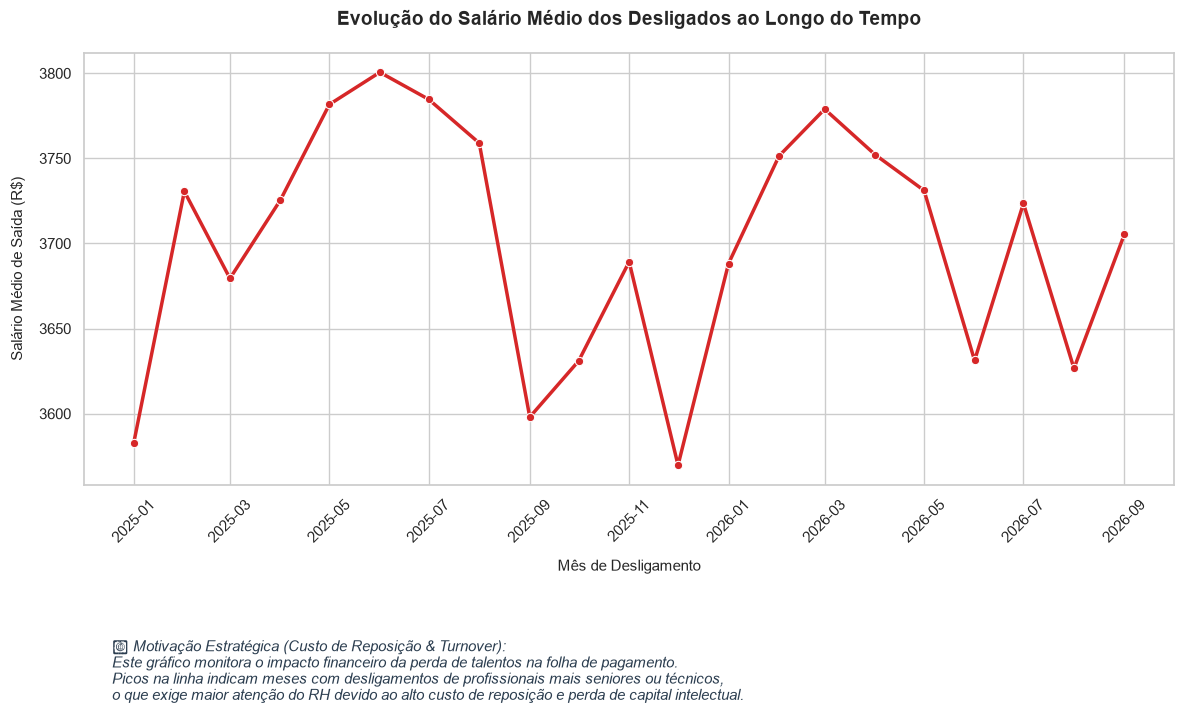

In [97]:
import matplotlib.pyplot as plt
import polars as pl
import seaborn as sns

# 1. Agrupar os dados por Mês de Desligamento e calcular a Média Salarial
# (Usando a variável 'df_final' do pipeline anterior que já possui os tipos corrigidos)
df_agrupado = (
    df_final
    # Ordenar as datas de desligamento ANTES de usar o group_by_dynamic
    .sort("DATA_DESLIGAMENTO_REF")
    .group_by_dynamic("DATA_DESLIGAMENTO_REF", every="1mo")
    .agg(pl.col("SALARIOS").mean().alias("SALARIO_MEDIO"))
    .collect()
)

# 2. Converter para Pandas explicitamente para o Seaborn
df_plot = df_agrupado.to_pandas()

# Verificar os dados que serão plotados no terminal
print("Evolução Mensal da Folha de Desligamento:")
print(df_plot.head())

# 3. Configurar o estilo do seaborn
sns.set_theme(style="whitegrid")

# Criar a figura e o eixo explicitamente
fig, ax = plt.subplots(figsize=(12, 6))

# Plotar a linha do tempo usando o seaborn
sns.lineplot(
    data=df_plot,
    x="DATA_DESLIGAMENTO_REF",
    y="SALARIO_MEDIO",
    ax=ax,
    marker="o",
    linewidth=2.5,
    color="#d62728",  # Cor alterada para vermelho (indica saídas/desligamentos)
)

# Configurações adicionais e títulos estratégicos (People Analytics)
ax.set_title(
    "Evolução do Salário Médio dos Desligados ao Longo do Tempo",
    fontsize=14,
    fontweight="bold",
    pad=20,
)
ax.set_xlabel("Mês de Desligamento", labelpad=10, fontsize=11)
ax.set_ylabel("Salário Médio de Saída (R$)", labelpad=10, fontsize=11)
ax.tick_params(axis="x", rotation=45)

# Nota motivacional de planejamento orçamentário adaptada para Desligamentos
texto_rh = (
    "💡 Motivação Estratégica (Custo de Reposição & Turnover):\n"
    "Este gráfico monitora o impacto financeiro da perda de talentos na folha de pagamento.\n"
    "Picos na linha indicam meses com desligamentos de profissionais mais seniores ou técnicos,\n"
    "o que exige maior atenção do RH devido ao alto custo de reposição e perda de capital intelectual."
)

# Ajuste fino na posição do texto para não cortar dependendo do ambiente
plt.figtext(
    0.1,
    -0.18,
    s=texto_rh,
    fontsize=10.5,
    color="#2c3e50",
    style="italic",
    horizontalalignment="left",
)

plt.tight_layout()
plt.show()


In [98]:
import polars as pl

# 1. Garantir que a coluna temporal esteja no tipo Date do Polars (ou extrair o Date do Datetime)
if df_agrupado["DATA_DESLIGAMENTO_REF"].dtype != pl.Date:
    df_agrupado = df_agrupado.with_columns(
        pl.col("DATA_DESLIGAMENTO_REF").cast(pl.Date)
    )

# 2. Calcular o tempo decorrido em meses usando expressões puras do Polars
# (Transforma as datas em uma sequência numérica de meses 0, 1, 2, 3... para preparar para regressões ou análises)
df_reg = df_agrupado.with_columns(
    (
        pl.col("DATA_DESLIGAMENTO_REF").dt.year() * 12
        + pl.col("DATA_DESLIGAMENTO_REF").dt.month()
        - (
            pl.col("DATA_DESLIGAMENTO_REF").min().dt.year() * 12
            + pl.col("DATA_DESLIGAMENTO_REF").min().dt.month()
        )
    ).alias("MESES_DESDE_INICIO")
)

# 3. Verificar o resultado na tela
print("--- Linha do Tempo Indexada por Meses (Desligamento Funcionários) ---")
print(
    df_reg.select(
        ["DATA_DESLIGAMENTO_REF", "SALARIO_MEDIO", "MESES_DESDE_INICIO"]
    ).head()
)


--- Linha do Tempo Indexada por Meses (Desligamento Funcionários) ---
shape: (5, 3)
┌───────────────────────┬───────────────┬────────────────────┐
│ DATA_DESLIGAMENTO_REF ┆ SALARIO_MEDIO ┆ MESES_DESDE_INICIO │
│ ---                   ┆ ---           ┆ ---                │
│ date                  ┆ f64           ┆ i32                │
╞═══════════════════════╪═══════════════╪════════════════════╡
│ 2025-01-01            ┆ 3583.040845   ┆ 0                  │
│ 2025-02-01            ┆ 3730.615422   ┆ 1                  │
│ 2025-03-01            ┆ 3679.468579   ┆ 2                  │
│ 2025-04-01            ┆ 3725.574703   ┆ 3                  │
│ 2025-05-01            ┆ 3781.692434   ┆ 4                  │
└───────────────────────┴───────────────┴────────────────────┘


--- Modelo de Tendência Salarial (Desligamento Funcionários) ---
Equação da reta: SALARIO_MEDIO = -0.64 * MESES_DESDE_INICIO + 3707.39
Coeficiente angular (Ritmo de variação R$/mês): R$ -0.64
Intercepto (Salário médio inicial estimado): R$ 3707.39

Métricas de Validação Estatística:
Coeficiente de Determinação (R²): 0.0032
Erro Quadrático Médio (MSE): 4688.71


c:\Users\MICRO\OneDrive\Documentos\UC2\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 128161 (\N{ELECTRIC LIGHT BULB}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\MICRO\OneDrive\Documentos\UC2\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 128201 (\N{CHART WITH DOWNWARDS TREND}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


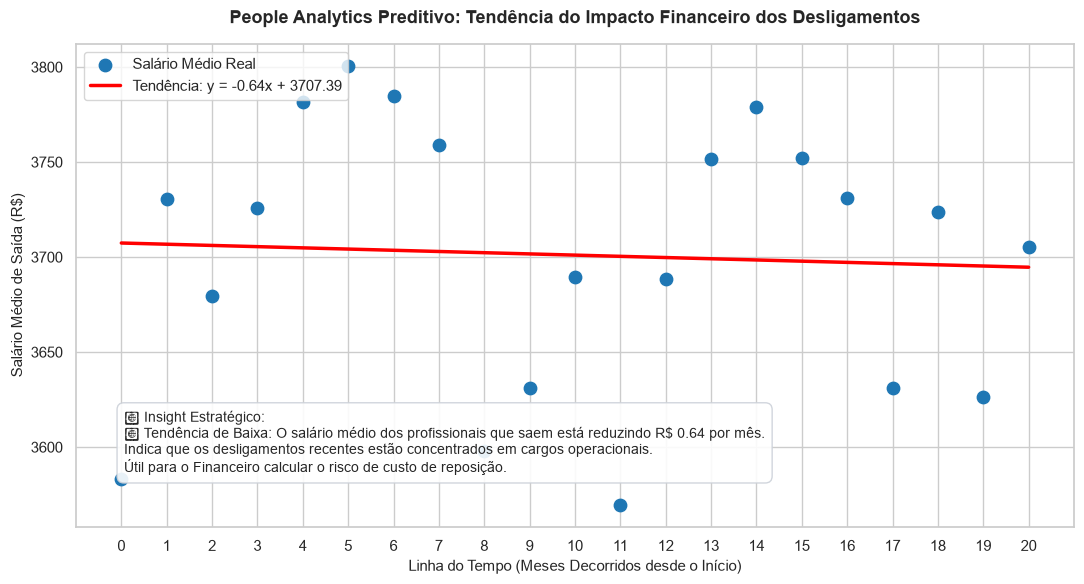

In [101]:
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

## 1. Preparar os dados para o modelo de Desligamentos
# Converter as colunas do Polars para arrays numpy
X = (
    df_reg["MESES_DESDE_INICIO"].to_numpy().reshape(-1, 1)
)  # Tempo decorrido (em meses)
y = df_reg["SALARIO_MEDIO"].to_numpy()  # Média salarial das pessoas desligadas

## 2. Criar e treinar o modelo preditivo
modelo = LinearRegression()
modelo.fit(X, y)

# Coeficientes do modelo
inclinacao = modelo.coef_[0]
intercepto = modelo.intercept_

print("--- Modelo de Tendência Salarial (Desligamento Funcionários) ---")
print(
    f"Equação da reta: SALARIO_MEDIO = {inclinacao:.2f} * MESES_DESDE_INICIO + {intercepto:.2f}"
)
print(f"Coeficiente angular (Ritmo de variação R$/mês): R$ {inclinacao:.2f}")
print(f"Intercepto (Salário médio inicial estimado): R$ {intercepto:.2f}")

## 3. Fazer as previsões para a linha de tendência
y_pred = modelo.predict(X)

## 4. Avaliar a precisão do modelo
r2 = r2_score(y, y_pred)
mse = mean_squared_error(y, y_pred)

print(f"\nMétricas de Validação Estatística:")
print(f"Coeficiente de Determinação (R²): {r2:.4f}")
print(f"Erro Quadrático Médio (MSE): {mse:.2f}")

## 5. Visualização Gráfica da Tendência do Impacto do Turnover
plt.figure(figsize=(11, 6))
sns.set_theme(style="whitegrid")

# Plotar dados reais das médias mensais (cor azul alterada para destacar os pontos reais)
plt.scatter(X, y, color="#1f77b4", s=80, label="Salário Médio Real", zorder=5)

# Plotar a linha de regressão (tendência de mercado)
plt.plot(
    X,
    y_pred,
    color="red",
    linewidth=2.5,
    label=f"Tendência: y = {inclinacao:.2f}x + {intercepto:.2f}",
)

# Configurações do gráfico voltadas para People Analytics e Planejamento Orçamentário
plt.title(
    "People Analytics Preditivo: Tendência do Impacto Financeiro dos Desligamentos",
    fontsize=13,
    fontweight="bold",
    pad=15,
)
plt.xlabel("Linha do Tempo (Meses Decorridos desde o Início)", fontsize=11)
plt.ylabel("Salário Médio de Saída (R$)", fontsize=11)
plt.xticks(
    np.arange(0, X.max() + 1, 1)
)  # Garante passos de 1 em 1 mês no eixo X

# Nota de interpretação corporativa adaptada para Desligamentos
if inclinacao > 0:
    interpretacao_texto = f"📈 Tendência de Alta: O salário médio dos profissionais que saem está subindo R$ {inclinacao:.2f} por mês."
    insight_adicional = "Alerta: Estamos perdendo profissionais progressivamente mais caros/seniores."
else:
    interpretacao_texto = f"📉 Tendência de Baixa: O salário médio dos profissionais que saem está reduzindo R$ {abs(inclinacao):.2f} por mês."
    insight_adicional = "Indica que os desligamentos recentes estão concentrados em cargos operacionais."

plt.figtext(
    0.12,
    0.20,
    s=f"💡 Insight Estratégico:\n{interpretacao_texto}\n{insight_adicional}\nÚtil para o Financeiro calcular o risco de custo de reposição.",
    fontsize=10,
    bbox=dict(
        facecolor="white", alpha=0.9, edgecolor="#ccd1d9", boxstyle="round,pad=0.5"
    ),
)

plt.legend(loc="upper left")
plt.tight_layout()
plt.show()


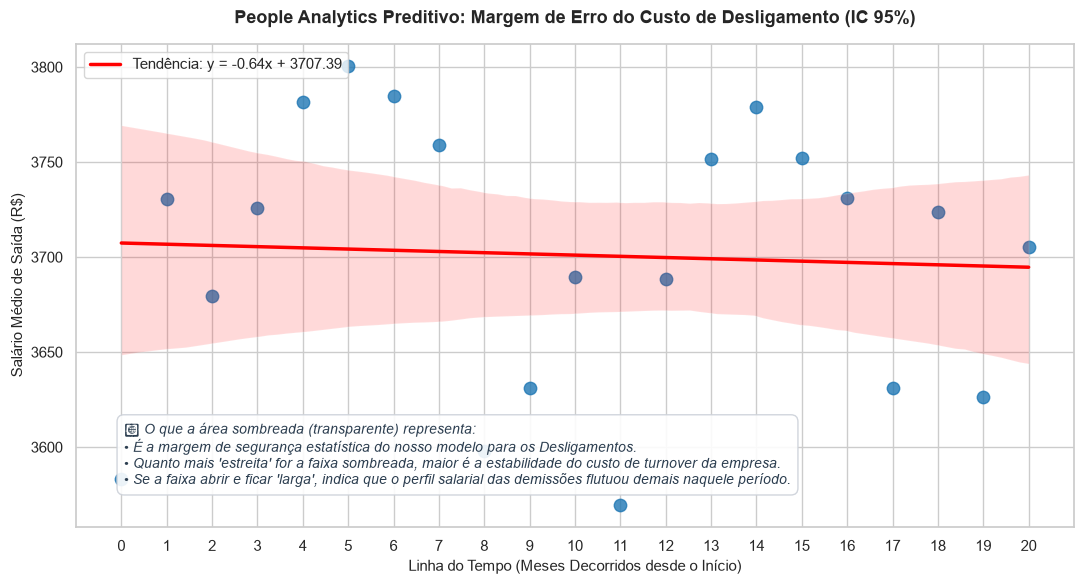

In [102]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

plt.figure(figsize=(11, 6))
sns.set_theme(style="whitegrid")

# Gerando o gráfico de regressão com intervalo de confiança (ci=95)
# .flatten() transforma a matriz X de volta em uma lista simples para o Seaborn
sns.regplot(
    x=X.flatten(),
    y=y,
    ci=95,
    scatter_kws={"color": "#1f77b4", "s": 80, "label": "Salário Médio Real"},
    line_kws={
        "color": "red",
        "linewidth": 2.5,
        "label": f"Tendência: y = {inclinacao:.2f}x + {intercepto:.2f}",
    },
)

# Títulos e legendas estratégicas (People Analytics)
plt.title(
    "People Analytics Preditivo: Margem de Erro do Custo de Desligamento (IC 95%)",
    fontsize=13,
    fontweight="bold",
    pad=15,
)
plt.xlabel("Linha do Tempo (Meses Decorridos desde o Início)", fontsize=11)
plt.ylabel("Salário Médio de Saída (R$)", fontsize=11)
plt.xticks(
    np.arange(0, X.max() + 1, 1)
)  # Garante passos de 1 em 1 mês no eixo X

# Nota explicativa sobre a área sombreada (Intervalo de Confiança) adaptada para Desligamentos
texto_rh = (
    "💡 O que a área sombreada (transparente) representa:\n"
    "• É a margem de segurança estatística do nosso modelo para os Desligamentos.\n"
    "• Quanto mais 'estreita' for a faixa sombreada, maior é a estabilidade do custo de turnover da empresa.\n"
    "• Se a faixa abrir e ficar 'larga', indica que o perfil salarial das demissões flutuou demais naquele período."
)
plt.figtext(
    0.12,
    0.18,
    s=texto_rh,
    fontsize=10,
    color="#2c3e50",
    style="italic",
    bbox=dict(
        facecolor="white", alpha=0.9, edgecolor="#ccd1d9", boxstyle="round,pad=0.5"
    ),
)

plt.legend(loc="upper left")
plt.tight_layout()
plt.show()
